# **CNN-FT — Modelo CNN**

Se selecciona el trial con menor `val_loss` del estudio Optuna (`OPT-CNN-FT`) y se entrena mediante **5-fold cross-validation** siguiendo el protocolo **LP-FT**, partiendo de los pesos del modelo CNN ganador de Fase 1. El modelo final se evalúa una única vez sobre el test de ICBA.

In [13]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import gc
import csv
import json
import time
import random
import subprocess
import numpy as np
import pandas as pd
import psutil
import pynvml
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from datetime import datetime
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score

In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_virtual_device_configuration(
        gpus[0],
        [tf.config.experimental.VirtualDeviceConfiguration(memory_limit=8192)]  # 8 GB
    )
    print(f'GPU encontrada: {gpus[0].name} (límite: 8 GB)')
else:
    print('No se encontró GPU, corriendo en CPU')

No se encontró GPU, corriendo en CPU


### **Configuración**

In [14]:
# --- PATHS ---
REPO_ROOT   = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
DATA_PATH   = Path.home() / 'pfc' / 'Dataset ICBA Folds'
MODELS_PATH = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 2' / 'Modelo CNN'
MODELS_PATH.mkdir(parents=True, exist_ok=True)

In [15]:
# --- SELECCIÓN DE ARQUITECTURA ---
ARQUITECTURA    = 'CNN-B'
BASE_MODEL_PATH = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 1' / 'CNN-B' / 'CNN-B-2.keras'

print(f'Modelo base : {BASE_MODEL_PATH}')
print(f'Existe      : {BASE_MODEL_PATH.exists()}')

# --- CONFIGURACIÓN GENERAL ---
DATASET       = 'ICBA'
OPTUNA_RUN_ID = 'OPT-CNN-FT'
NUM_CLASSES   = 4
CLASSES       = ['Am', 'HTA', 'EAo', 'MCH']
ALL_FOLDS     = [1, 2, 3, 4, 5]

IMG_HEIGHT = 192
IMG_WIDTH  = 352
CHANNELS   = 1
BATCH_SIZE = 16
SEED       = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED']         = str(SEED)
os.environ['TF_DETERMINISTIC_OPS']   = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
tf.config.experimental.enable_op_determinism()

# Protocolo LP-FT (mismos valores que OPT-CNN-FT-2)
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCH_MAX     = 100
LP_LR         = 1e-3
LP_EPOCHS     = 10

# Callbacks (mismos valores que OPT-CNN-FT-2)
ES_PATIENCE   = 8
ES_MIN_DELTA  = 0.0001
RLR_FACTOR    = 0.5
RLR_PATIENCE  = 5
RLR_MIN_DELTA = 0.0001
RLR_MIN_LR    = 1e-7

Modelo base : C:\Users\Victoria\Desktop\TESIS_bioingenieria_JonquieresOrsi\Códigos\Modelos\Fase 1\CNN-B\CNN-B-2.keras
Existe      : True


In [5]:
def set_fine_tune_layers(backbone, ft_blocks):
    pool_indices = [i for i, l in enumerate(backbone.layers)
                    if isinstance(l, tf.keras.layers.MaxPooling2D)]
    start_idx = pool_indices[-(ft_blocks + 1)] + 1
    for i, layer in enumerate(backbone.layers):
        layer.trainable = (i >= start_idx)

### **Selección del Top-1**

Se carga el CSV del estudio Optuna y se selecciona el trial completado con menor `val_loss`.

In [6]:
# --- Top-1 Optuna ---
df_opt      = pd.read_csv(MODELS_PATH / f'{OPTUNA_RUN_ID}.csv', index_col='trial')
df_complete = df_opt[df_opt['state'] == 'COMPLETE'].copy()
top1        = df_complete.sort_values('value').head(1)

CONFIGS = []
for _, (trial_num, row) in enumerate(top1.iterrows()):
    CONFIGS.append({
        'run_id':           'CNN-FT',
        'optuna_trial':     int(trial_num),
        'optuna_val_loss':  float(row['value']),
        'dense_units':      int(row['dense_units']),
        'ft_blocks':        int(row['ft_blocks']),
        'learning_rate_ft': float(row['learning_rate_ft']),
    })

In [7]:
cfg = CONFIGS[0]
print(f"{cfg['run_id']}  (trial Optuna #{cfg['optuna_trial']} — val_loss FT: {cfg['optuna_val_loss']:.4f})")
print(f"  dense_units      : {cfg['dense_units']}")
print(f"  ft_blocks        : {cfg['ft_blocks']}")
print(f"  learning_rate_lp : {LP_LR:.2e}  (fijo)")
print(f"  learning_rate_ft : {cfg['learning_rate_ft']:.2e}")

CNN-FT  (trial Optuna #9 — val_loss FT: 0.7596)
  dense_units      : 128
  ft_blocks        : 2
  learning_rate_lp : 1.00e-03  (fijo)
  learning_rate_ft : 8.69e-05


### **Carga de Datos**

In [16]:
AUTOTUNE = tf.data.AUTOTUNE

def load_fold_images(fold_dirs, classes):
    X, y = [], []
    for fold_dir in fold_dirs:
        for label_idx, cls in enumerate(classes):
            cls_dir = Path(fold_dir) / cls
            if not cls_dir.exists():
                print(f'  Advertencia: {cls_dir} no existe')
                continue
            for f in sorted(cls_dir.iterdir()):
                if f.suffix.lower() in ('.jpg', '.jpeg'):
                    img = np.array(Image.open(f).convert('L'))
                    img = img[:, :, np.newaxis]   # H×W×1 grayscale
                    X.append(img)
                    y.append(label_idx)
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int32)

print('Cargando folds en memoria...')
X_folds, y_folds = {}, {}
for fold in ALL_FOLDS:
    fold_dir = DATA_PATH / 'train' / f'fold {fold}'
    X_folds[fold], y_folds[fold] = load_fold_images([fold_dir], CLASSES)
    counts = {cls: int((y_folds[fold] == i).sum()) for i, cls in enumerate(CLASSES)}
    print(f'  fold {fold}: {X_folds[fold].shape[0]} imgs  {counts}')

print('\nCargando test...')
X_test, y_test = load_fold_images([DATA_PATH / 'test'], CLASSES)
counts_test    = {cls: int((y_test == i).sum()) for i, cls in enumerate(CLASSES)}
print(f'  test : {X_test.shape[0]} imgs  {counts_test}')

total_train = sum(X_folds[f].shape[0] for f in ALL_FOLDS)
print(f'\nTotal train (5 folds): {total_train} | Test: {X_test.shape[0]}')

Cargando folds en memoria...
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 1\Am no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 1\HTA no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 1\EAo no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 1\MCH no existe
  fold 1: 0 imgs  {'Am': 0, 'HTA': 0, 'EAo': 0, 'MCH': 0}
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 2\Am no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 2\HTA no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 2\EAo no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 2\MCH no existe
  fold 2: 0 imgs  {'Am': 0, 'HTA': 0, 'EAo': 0, 'MCH': 0}
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 3\Am no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 3\HTA no existe
  Advertencia: C:\Users\Vict

### **Arquitectura**

Se parte del modelo CNN ganador de Fase 1. El backbone conserva los pesos aprendidos sobre el dataset sintético. Se reemplaza la cabeza clasificadora de 5 clases por una nueva de 4 clases (Am, HTA, EAo, MCH).

El entrenamiento sigue el protocolo **LP-FT**:
- **Fase LP** (`LP_EPOCHS` épocas): backbone congelado, solo se entrena la nueva cabeza con `LP_LR = 1e-3`.
- **Fase FT** (hasta `EPOCH_MAX` épocas con early stopping): se descongelan los últimos `ft_blocks` bloques del backbone usando `MaxPooling2D` como delimitadores, con `learning_rate_ft` buscado por Optuna.

Las imágenes se cargan en escala de grises (1 canal), consistente con el pipeline de Fase 1 de los modelos CNN. La normalización se aplica en el pipeline de datos.

In [9]:
def build_cnn_b_ft(model_path, dense_units, input_shape=(192, 352, 1), num_classes=4):
    src_model = tf.keras.models.load_model(model_path)
    gap       = next(l for l in src_model.layers if isinstance(l, tf.keras.layers.GlobalAveragePooling2D))
    backbone  = tf.keras.Model(inputs=src_model.input, outputs=gap.output, name='cnn_b_backbone')
    backbone.trainable = False
    del src_model

    inputs = tf.keras.Input(shape=input_shape)
    x = backbone(inputs)
    x = layers.Dense(dense_units, activation='relu', name='head_dense')(x)
    x = layers.Dropout(0.5, name='head_dropout')(x)
    x = layers.Dense(num_classes, activation='softmax', name='head_output')(x)
    model = tf.keras.Model(inputs=inputs, outputs=x, name='CNN_B_Phase2')
    return model, backbone

build_cnn_ft = build_cnn_b_ft

### **Monitoreo de Recursos y Logging**

In [10]:
def _append_csv(filepath, row):
    filepath  = Path(filepath)
    write_hdr = not filepath.exists()
    with open(filepath, 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=row.keys())
        if write_hdr:
            w.writeheader()
        w.writerow(row)

try:
    pynvml.nvmlInit()
    _GPU_HANDLE    = pynvml.nvmlDeviceGetHandleByIndex(0)
    _GPU_AVAILABLE = True
except Exception:
    _GPU_AVAILABLE = False

class ResourceMonitor(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.ram_max  = 0.0
        self.vram_max = 0.0
        self._pid     = os.getpid()

    def on_epoch_end(self, epoch, logs=None):
        self.ram_max = max(self.ram_max, psutil.Process().memory_info().rss / 1e9)
        if _GPU_AVAILABLE:
            for proc in pynvml.nvmlDeviceGetComputeRunningProcesses(_GPU_HANDLE):
                if proc.pid == self._pid:
                    self.vram_max = max(self.vram_max, proc.usedGpuMemory / 1e9)
                    break


def log_training(cfg, val_fold, train_folds, history_lp, history_ft, monitor, t_start, t_end,
                 model_path, lp_hist_path, ft_hist_path):
    best_ep = int(np.argmin(history_ft.history['val_loss']))
    row = {
        'run_id':           cfg['run_id'],
        'val_fold':         val_fold,
        'train_folds':      ','.join(str(f) for f in train_folds),
        'fecha':            datetime.now().strftime('%d/%m/%Y'),
        'arquitectura':     ARQUITECTURA,
        'base_model_id':    BASE_MODEL_PATH.stem,
        'dataset':          DATASET,
        'img_width':        IMG_WIDTH,
        'img_height':       IMG_HEIGHT,
        'channels':         CHANNELS,
        'batch_size':       BATCH_SIZE,
        'seed':             SEED,
        'optuna_run_id':    f"{OPTUNA_RUN_ID}_trial{cfg['optuna_trial']}",
        'dense_units':      cfg['dense_units'],
        'ft_blocks':        cfg['ft_blocks'],
        'learning_rate_lp': LP_LR,
        'learning_rate_ft': cfg['learning_rate_ft'],
        'loss_function':    LOSS_FUNCTION,
        'lp_epochs':        LP_EPOCHS,
        'epochs_ft':        len(history_ft.history['val_loss']),
        'best_epoch_ft':    best_ep + 1,
        'es_patience':      ES_PATIENCE,
        'es_min_delta':     ES_MIN_DELTA,
        'rlr_factor':       RLR_FACTOR,
        'rlr_patience':     RLR_PATIENCE,
        'rlr_min_delta':    RLR_MIN_DELTA,
        'rlr_min_lr':       RLR_MIN_LR,
        'epoch_max':        EPOCH_MAX,
        't_start':          datetime.fromtimestamp(t_start).strftime('%d/%m - %H:%M:%S'),
        't_end':            datetime.fromtimestamp(t_end).strftime('%d/%m - %H:%M:%S'),
        't_min':            round((t_end - t_start) / 60, 2),
        'ram_max_gb':       round(monitor.ram_max, 2),
        'vram_max_gb':      round(monitor.vram_max, 2),
        'model_path':       str(model_path.relative_to(REPO_ROOT)),
        'lp_history_path':  str(lp_hist_path.relative_to(REPO_ROOT)),
        'ft_history_path':  str(ft_hist_path.relative_to(REPO_ROOT)),
    }
    _append_csv(MODELS_PATH / 'CNN_FT_training.csv', row)
    print(f"  CNN_FT_training.csv actualizado — fold {val_fold}")

### **Entrenamiento con Cross-Validation**

Se entrena el top-1 con **5-fold cross-validation** siguiendo el protocolo LP-FT. Por cada fold se guarda el modelo (`.keras`) y los historiales de entrenamiento (`.json`).

In [ ]:
HISTORIES_CV = {}

for cfg in CONFIGS:
    run_id = cfg['run_id']
    print(f'\n{"="*65}')
    print(f'{run_id}  (trial #{cfg["optuna_trial"]} — dense_units={cfg["dense_units"]}, ft_blocks={cfg["ft_blocks"]}, lr_ft={cfg["learning_rate_ft"]:.2e})')
    print(f'{"="*65}')

    HISTORIES_CV[run_id] = []
    val_losses = []
    val_accs   = []

    for val_fold in ALL_FOLDS:
        train_folds_cv = [f for f in ALL_FOLDS if f != val_fold]
        print(f'\n  Fold val={val_fold}  |  train={train_folds_cv}')

        tf.keras.backend.clear_session()
        gc.collect()
        random.seed(SEED)
        np.random.seed(SEED)
        tf.random.set_seed(SEED)

        X_train_cv = np.concatenate([X_folds[f] for f in train_folds_cv])
        y_train_cv = np.concatenate([y_folds[f] for f in train_folds_cv])
        X_val_cv   = X_folds[val_fold]
        y_val_cv   = y_folds[val_fold]

        np.random.seed(SEED)
        idx        = np.random.permutation(len(X_train_cv))
        X_train_cv = X_train_cv[idx]
        y_train_cv = y_train_cv[idx]

        train_ds = (
            tf.data.Dataset.from_tensor_slices((X_train_cv, y_train_cv))
            .shuffle(len(X_train_cv), seed=SEED, reshuffle_each_iteration=True)
            .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE)
        )
        val_ds = (
            tf.data.Dataset.from_tensor_slices((X_val_cv, y_val_cv))
            .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE)
        )

        model, backbone  = build_cnn_ft(BASE_MODEL_PATH, cfg['dense_units'])
        resource_monitor = ResourceMonitor()
        checkpoint_path  = MODELS_PATH / f'CNN-FT-{val_fold}.keras'
        lp_hist_path     = MODELS_PATH / f'CNN-FT-{val_fold}_history_lp.json'
        ft_hist_path     = MODELS_PATH / f'CNN-FT-{val_fold}_history_ft.json'

        # Fase LP
        model.compile(
            optimizer = tf.keras.optimizers.Adam(learning_rate=LP_LR),
            loss      = LOSS_FUNCTION,
            metrics   = ['accuracy'],
        )
        t_start    = time.time()
        history_lp = model.fit(
            train_ds, validation_data=val_ds,
            epochs=LP_EPOCHS, callbacks=[resource_monitor], verbose=0,
        )
        with open(lp_hist_path, 'w') as f:
            json.dump(history_lp.history, f)

        # Fase FT
        set_fine_tune_layers(backbone, cfg['ft_blocks'])
        model.compile(
            optimizer = tf.keras.optimizers.Adam(learning_rate=cfg['learning_rate_ft']),
            loss      = LOSS_FUNCTION,
            metrics   = ['accuracy'],
        )
        history_ft = model.fit(
            train_ds, validation_data=val_ds, epochs=EPOCH_MAX,
            callbacks=[
                EarlyStopping(monitor='val_loss', patience=ES_PATIENCE, min_delta=ES_MIN_DELTA,
                              restore_best_weights=True),
                ReduceLROnPlateau(monitor='val_loss', factor=RLR_FACTOR, patience=RLR_PATIENCE,
                                  min_delta=RLR_MIN_DELTA, min_lr=RLR_MIN_LR),
                ModelCheckpoint(filepath=checkpoint_path, monitor='val_loss', save_best_only=True, verbose=0),
                resource_monitor,
            ],
            verbose=1,
        )
        t_end = time.time()
        with open(ft_hist_path, 'w') as f:
            json.dump(history_ft.history, f)

        HISTORIES_CV[run_id].append({'lp': history_lp.history, 'ft': history_ft.history})
        log_training(cfg, val_fold, train_folds_cv, history_lp, history_ft, resource_monitor,
                     t_start, t_end, checkpoint_path, lp_hist_path, ft_hist_path)

        best_ep   = int(np.argmin(history_ft.history['val_loss']))
        best_loss = round(history_ft.history['val_loss'][best_ep], 4)
        best_acc  = round(history_ft.history['val_accuracy'][best_ep], 4)
        epochs_ft = len(history_ft.history['val_loss'])
        val_losses.append(best_loss)
        val_accs.append(best_acc)
        print(f'    val_loss={best_loss:.4f} | val_acc={best_acc:.4f} | epochs_ft={epochs_ft} | {round((t_end - t_start)/60, 1)} min')

        del model, backbone, train_ds, val_ds, history_lp, history_ft, X_train_cv, y_train_cv, resource_monitor
        gc.collect()
        tf.keras.backend.clear_session()
        gc.collect()

    mean_loss = float(np.mean(val_losses))
    mean_acc  = float(np.mean(val_accs))
    print(f'\n  {run_id} CV (val): val_loss={mean_loss:.4f} | val_acc={mean_acc:.4f}')

print('\nCross-validation completada.')

### **Resultados**

#### **Reconstrucción de contexto tras reinicio de kernel**

Correr la siguiente celda **solo si el kernel fue reiniciado** después del entrenamiento. Antes de correrla, ejecutar todas las celdas anteriores al bloque de entrenamiento.

In [17]:
# ── RECONSTRUCCIÓN DE CONTEXTO ────────────────────────────────────────────────
df_opt      = pd.read_csv(MODELS_PATH / f'{OPTUNA_RUN_ID}.csv', index_col='trial')
df_complete = df_opt[df_opt['state'] == 'COMPLETE'].copy()
top1        = df_complete.sort_values('value').head(1)

CONFIGS = []
for _, (trial_num, row) in enumerate(top1.iterrows()):
    CONFIGS.append({
        'run_id':           'CNN-FT',
        'optuna_trial':     int(trial_num),
        'optuna_val_loss':  float(row['value']),
        'dense_units':      int(row['dense_units']),
        'ft_blocks':        int(row['ft_blocks']),
        'learning_rate_ft': float(row['learning_rate_ft']),
    })

HISTORIES_CV = {}
for cfg in CONFIGS:
    run_id = cfg['run_id']
    HISTORIES_CV[run_id] = []
    for val_fold in ALL_FOLDS:
        with open(MODELS_PATH / f'CNN-FT-{val_fold}_history_lp.json') as f:
            h_lp = json.load(f)
        with open(MODELS_PATH / f'CNN-FT-{val_fold}_history_ft.json') as f:
            h_ft = json.load(f)
        HISTORIES_CV[run_id].append({'lp': h_lp, 'ft': h_ft})

print('Contexto reconstruido.')
cfg         = CONFIGS[0]
best_losses = [min(h['ft']['val_loss']) for h in HISTORIES_CV[cfg['run_id']]]
print(f"  {cfg['run_id']}: val_loss_mean={float(np.mean(best_losses)):.4f}")

Contexto reconstruido.
  CNN-FT: val_loss_mean=0.8424


#### **Curvas de Entrenamiento**

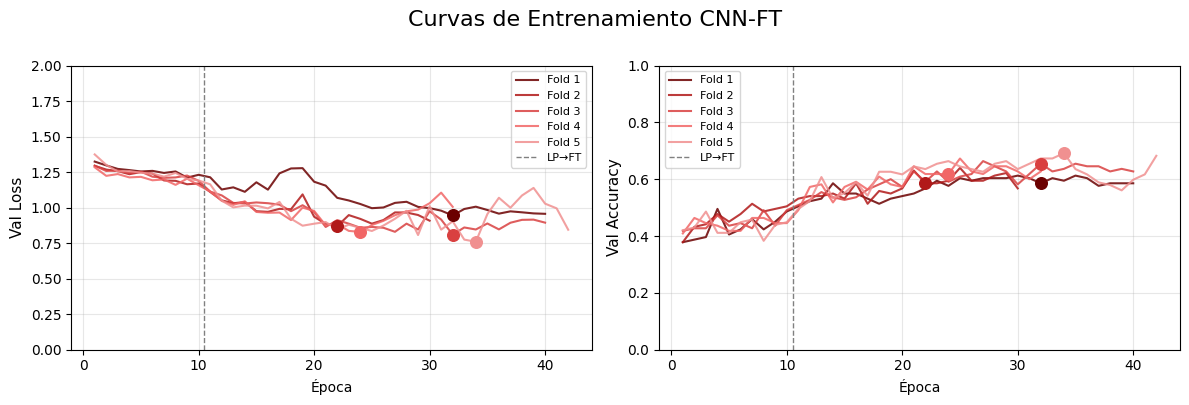

Guardado en C:\Users\Victoria\Desktop\TESIS_bioingenieria_JonquieresOrsi\Informe Final\Imágenes\Curvas CNN-FT.png


In [18]:
FOLD_COLORS = ['#6B0000', '#B11919', '#D94040', '#F16666', '#F09090']

cfg    = CONFIGS[0]
run_id = cfg['run_id']
hs     = HISTORIES_CV[run_id]

vl_all   = [h['lp']['val_loss']     + h['ft']['val_loss']     for h in hs]
va_all   = [h['lp']['val_accuracy'] + h['ft']['val_accuracy'] for h in hs]
best_eps = [LP_EPOCHS + int(np.argmin(h['ft']['val_loss'])) + 1 for h in hs]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4))

for i, (fold, vl, va, be) in enumerate(zip(ALL_FOLDS, vl_all, va_all, best_eps)):
    color = FOLD_COLORS[i]
    eps   = np.arange(1, len(vl) + 1)
    ax0.plot(eps, vl, color=color, linewidth=1.5, label=f'Fold {fold}', alpha=0.85)
    ax0.scatter([be], [vl[be - 1]], color=color, s=70, zorder=5)
    ax1.plot(eps, va, color=color, linewidth=1.5, label=f'Fold {fold}', alpha=0.85)
    ax1.scatter([be], [va[be - 1]], color=color, s=70, zorder=5)

for ax in [ax0, ax1]:
    ax.axvline(LP_EPOCHS + 0.5, color='gray', linestyle='--', linewidth=1, label='LP→FT')
    ax.set_xlabel('Época')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

ax0.set_ylabel('Val Loss',     fontsize=11)
ax0.set_ylim(0, 2)
ax1.set_ylabel('Val Accuracy', fontsize=11)
ax1.set_ylim(0, 1)

plt.suptitle(f'Curvas de Entrenamiento {run_id}', fontsize=16, y=1)
plt.tight_layout()

out_path = REPO_ROOT / 'Informe Final' / 'Imágenes' / f'Curvas {run_id}.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Guardado en {out_path}')

#### **Evaluación en Test**

In [14]:
def log_results(run_id, val_fold, train_folds, history_ft, y_true, y_pred, test_loss, test_acc):
    best_ep = int(np.argmin(history_ft['val_loss']))
    report  = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True, zero_division=0)
    row = {
        'run_id':        run_id,
        'val_fold':      val_fold,
        'train_folds':   ','.join(str(f) for f in train_folds),
        'best_epoch_ft': best_ep + 1,
        'best_val_loss': round(history_ft['val_loss'][best_ep], 4),
        'best_val_acc':  round(history_ft['val_accuracy'][best_ep], 4),
        'test_loss':     round(test_loss, 4),
        'test_acc':      round(test_acc, 4),
        'balanced_acc':  round(balanced_accuracy_score(y_true, y_pred), 4),
        'macro_f1':      round(report['macro avg']['f1-score'], 4),
        'weighted_f1':   round(report['weighted avg']['f1-score'], 4),
        **{f'precision_{cls}': round(report[cls]['precision'], 4) for cls in CLASSES},
        **{f'recall_{cls}':    round(report[cls]['recall'],    4) for cls in CLASSES},
        **{f'f1_{cls}':        round(report[cls]['f1-score'],  4) for cls in CLASSES},
        **{f'support_{cls}':   int(report[cls]['support'])        for cls in CLASSES},
    }
    _append_csv(MODELS_PATH / 'CNN_FT_results.csv', row)
    return row


# Limpiar CSV si existe (evita duplicados al re-ejecutar la celda)
results_csv = MODELS_PATH / 'CNN_FT_results.csv'
if results_csv.exists():
    results_csv.unlink()

cfg       = CONFIGS[0]
run_id    = cfg['run_id']
fold_rows = []
TEST_PREDS = {run_id: {'fold_preds': [], 'y_true': y_test}}

print(f'Evaluando 5 modelos CNN-FT en test...\n')
for val_fold in ALL_FOLDS:
    train_folds_cv = [f for f in ALL_FOLDS if f != val_fold]

    with open(MODELS_PATH / f'CNN-FT-{val_fold}_history_ft.json') as f:
        history_ft = json.load(f)

    test_ds = (
        tf.data.Dataset.from_tensor_slices((X_test, y_test))
        .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

    model      = tf.keras.models.load_model(MODELS_PATH / f'CNN-FT-{val_fold}.keras')
    y_pred     = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    TEST_PREDS[run_id]['fold_preds'].append(y_pred)
    del model
    tf.keras.backend.clear_session()
    gc.collect()

    row = log_results(run_id, val_fold, train_folds_cv, history_ft, y_test, y_pred, test_loss, test_acc)
    fold_rows.append(row)
    print(f'  CNN-FT-{val_fold}: balanced_acc={row["balanced_acc"]:.4f} | macro_f1={row["macro_f1"]:.4f}')

mean_bacc = float(np.mean([r['balanced_acc'] for r in fold_rows]))
mean_f1   = float(np.mean([r['macro_f1']     for r in fold_rows]))
print(f'\n  mean : balanced_acc={mean_bacc:.4f} | macro_f1={mean_f1:.4f}')
print('\nCNN_FT_results.csv guardado.')

Evaluando 5 modelos CNN-FT en test...

  CNN-FT-1: balanced_acc=0.6581 | macro_f1=0.6545
  CNN-FT-2: balanced_acc=0.6446 | macro_f1=0.6385
  CNN-FT-3: balanced_acc=0.7279 | macro_f1=0.7305
  CNN-FT-4: balanced_acc=0.6226 | macro_f1=0.6182
  CNN-FT-5: balanced_acc=0.7204 | macro_f1=0.7238

  mean : balanced_acc=0.6747 | macro_f1=0.6731

CNN_FT_results.csv guardado.


#### **Tabla de Resultados**

In [15]:
df_res = pd.read_csv(MODELS_PATH / 'CNN_FT_results.csv')

df_res['macro_precision'] = df_res[[f'precision_{cls}' for cls in CLASSES]].mean(axis=1).round(4)
df_res['macro_recall']    = df_res[[f'recall_{cls}'    for cls in CLASSES]].mean(axis=1).round(4)

col_map = {
    'balanced_acc':    'Balanced Accuracy',
    'test_acc':        'Accuracy',
    'macro_precision': 'Precision',
    'macro_recall':    'Recall',
    'macro_f1':        'F1-macro',
    'f1_Am':           'F1-Am',
    'f1_HTA':          'F1-HTA',
    'f1_EAo':          'F1-EAo',
    'f1_MCH':          'F1-MCH',
    'val_fold':        'Fold',
}

df_table = df_res[list(col_map.keys())].rename(columns=col_map).copy()
df_table['Fold'] = df_table['Fold'].astype(str)

# Fila de media
mean_vals         = df_table.drop(columns='Fold').mean().round(4)
mean_row          = mean_vals.to_frame().T
mean_row['Fold']  = 'Media'
df_table          = pd.concat([df_table, mean_row], ignore_index=True)

# Reordenar columnas: Fold al final
metric_cols = [c for c in df_table.columns if c != 'Fold']
df_table    = df_table[metric_cols + ['Fold']]

fmt = {c: '{:.4f}' for c in metric_cols}
display(df_table.style.format(fmt, na_rep='-').hide(axis='index'))

Balanced Accuracy,Accuracy,Precision,Recall,F1-macro,F1-Am,F1-HTA,F1-EAo,F1-MCH,Fold
0.6581,0.6861,0.7302,0.6581,0.6545,0.7857,0.7324,0.6429,0.4571,1
0.6446,0.6715,0.6554,0.6446,0.6385,0.7848,0.7027,0.6667,0.4000,2
0.7279,0.7372,0.7372,0.7279,0.7305,0.8421,0.7353,0.6914,0.6531,3
0.6226,0.6496,0.6741,0.6226,0.6182,0.7561,0.6250,0.6593,0.4324,4
0.7204,0.7372,0.7574,0.7204,0.7238,0.8148,0.7436,0.7027,0.6341,5
0.6747,0.6963,0.7109,0.6747,0.6731,0.7967,0.7078,0.6726,0.5153,Media


---

# **CNN-Final - Modelo CNN Final**

Se reentrena la configuración ganadora de Optuna sobre la totalidad de los datos de entrenamiento (5 folds). El número de épocas se fija como la mediana de los `best_epoch` obtenidos en el cross-validation. El número de épocas de la fase LP se mantiene igual que en el CV. No se usan callbacks de Early Stopping ni ReduceLROnPlateau porque no hay val_loss para monitorear.

Al finalizar se evalúa una única vez sobre el conjunto de test. 

In [20]:
cfg    = CONFIGS[0]
run_id = 'CNN-FINAL'

best_epochs_ft = [int(np.argmin(h['ft']['val_loss'])) + 1 for h in HISTORIES_CV[cfg['run_id']]]
median_ep      = int(np.median(best_epochs_ft))

print(f'best_epoch_ft por fold : {best_epochs_ft}')
print(f'Mediana                : {median_ep} épocas FT')

best_epoch_ft por fold : [22, 12, 22, 14, 24]
Mediana                : 22 épocas FT


In [ ]:
tf.keras.backend.clear_session(); gc.collect()
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

X_all_b = np.concatenate([X_folds[f] for f in ALL_FOLDS])
y_all_b = np.concatenate([y_folds[f] for f in ALL_FOLDS])
np.random.seed(SEED)
idx_b = np.random.permutation(len(X_all_b))
X_all_b, y_all_b = X_all_b[idx_b], y_all_b[idx_b]

train_ds_b_tr = (
    tf.data.Dataset.from_tensor_slices((X_all_b, y_all_b))
    .shuffle(len(X_all_b), seed=SEED, reshuffle_each_iteration=True)
    .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE)
)

model_b_tr, backbone_b_tr = build_cnn_ft(BASE_MODEL_PATH, cfg['dense_units'])

# Fase LP
model_b_tr.compile(optimizer=tf.keras.optimizers.Adam(LP_LR), loss=LOSS_FUNCTION, metrics=['accuracy'])
print(f'LP — {LP_EPOCHS} epocas')
model_b_tr.fit(train_ds_b_tr, epochs=LP_EPOCHS, verbose=1)

# Fase FT
set_fine_tune_layers(backbone_b_tr, cfg['ft_blocks'])
model_b_tr.compile(optimizer=tf.keras.optimizers.Adam(cfg['learning_rate_ft']), loss=LOSS_FUNCTION, metrics=['accuracy'])
print(f'\nFT — {median_ep} epocas (mediana de best_epochs_ft)')
t0 = time.time()
model_b_tr.fit(train_ds_b_tr, epochs=median_ep, verbose=1)
print(f'Tiempo FT: {(time.time()-t0)/60:.1f} min')

model_b_tr.save(MODELS_PATH / 'CNN-FINAL.keras')
print('CNN-FINAL.keras guardado')

del model_b_tr, backbone_b_tr, train_ds_b_tr, X_all_b, y_all_b
gc.collect() 
tf.keras.backend.clear_session()
gc.collect()

LP — 10 epocas
Epoch 1/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3169 - loss: 1.6104
Epoch 2/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.3661 - loss: 1.3161
Epoch 3/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.3770 - loss: 1.3014
Epoch 4/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.3934 - loss: 1.2795
Epoch 5/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4117 - loss: 1.2553
Epoch 6/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4171 - loss: 1.2587
Epoch 7/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4262 - loss: 1.2305
Epoch 8/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4444 - loss: 1.2366
Epoch 9/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4645 - loss: 1.2099
Epoch 10/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.4718 - loss: 1.1920

FT — 22 epocas (mediana de best_epochs_ft)
Epoch 1/22
35/35 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.4900 - loss: 1.1642
Epoch

0

#### **Resultados**

In [ ]:
test_ds_b = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE)
)
_m_b     = tf.keras.models.load_model(MODELS_PATH / 'CNN-FINAL.keras')
probs_b  = _m_b.predict(test_ds_b, verbose=0)
y_pred_b = np.argmax(probs_b, axis=1)
del _m_b; gc.collect(); tf.keras.backend.clear_session(); gc.collect()

report_b = classification_report(y_test, y_pred_b, target_names=CLASSES, output_dict=True, zero_division=0)
ba_b     = balanced_accuracy_score(y_test, y_pred_b)
row_b    = {
    'Modelo': f'CNN-FINAL',
    'Balanced Accuracy': round(ba_b, 4),
    'Accuracy':          round((y_pred_b == y_test).mean(), 4),
    'Precision':         round(float(np.mean([report_b[c]['precision'] for c in CLASSES])), 4),
    'Recall':            round(float(np.mean([report_b[c]['recall']    for c in CLASSES])), 4),
    'F1-macro':          round(report_b['macro avg']['f1-score'], 4),
    'F1-Am':  round(report_b['Am']['f1-score'],  4),
    'F1-HTA': round(report_b['HTA']['f1-score'], 4),
    'F1-EAo': round(report_b['EAo']['f1-score'], 4),
    'F1-MCH': round(report_b['MCH']['f1-score'], 4),
}
_mcols_b = [c for c in row_b if c != 'Modelo']

Modelo,Balanced Accuracy,Accuracy,Precision,Recall,F1-macro,F1-Am,F1-HTA,F1-EAo,F1-MCH
CNN-FINAL,0.6673,0.6861,0.7422,0.6673,0.6671,0.7692,0.5862,0.6977,0.6154


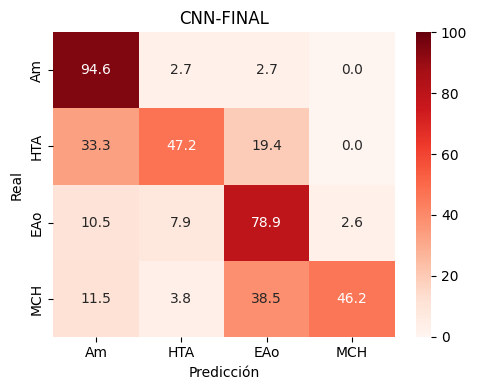

In [24]:
# Métricas
display(pd.DataFrame([row_b]).style.format({c: '{:.4f}' for c in _mcols_b}).hide(axis='index'))

# Martiz de confusión
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_b, normalize='true') * 100,
            annot=True, fmt='.1f', cmap='Reds',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, vmin=0, vmax=100)
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title(f'CNN-FINAL')
plt.tight_layout() 
plt.show()